# Eleflai YOLO Inference Workflow Demo

This notebook demonstrates the inference workflow for the Eleflai YOLO detector using a small de-identified GitHub demo image set: image loading, checkpoint initialization, inference, post-processing, annotated visualization, and structured output generation.

**Transparency note.** The public repository does not include unrestricted pretrained weights. To run model inference, place an authorized or local demo checkpoint at `weights/eleflai_yolo_demo.pt`, or update `WEIGHTS_PATH` below.


## 1. Configuration

The detector class abbreviations follow the manuscript: `TM`, `SPM`, `PF`, `BE`, `TMC`, `TMP`, `HE`, `FG`, `SE`, `CE`, and `ACTM`.


In [1]:
from __future__ import annotations

import json
import math
import random
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageDraw, ImageOps

try:
    from ultralytics import YOLO
except ImportError:
    YOLO = None

SEED = 42
random.seed(SEED)

CLASS_NAMES = {
    0: "TM",
    1: "SPM",
    2: "TMC",
    3: "CE",
    4: "BE",
    5: "TMP",
    6: "ACTM",
    7: "HE",
    8: "FG",
    9: "SE",
    10: "PF",
}

PALETTE = {
    0: (74, 144, 226),
    1: (126, 211, 33),
    2: (245, 166, 35),
    3: (189, 16, 224),
    4: (80, 227, 194),
    5: (248, 231, 28),
    6: (144, 19, 254),
    7: (65, 117, 5),
    8: (208, 2, 27),
    9: (0, 188, 212),
    10: (255, 112, 67),
}

DATA_YAML_PATH = Path("demo_assets/github_demo_dataset.yaml")
YAML_SPLIT = "demo"
WEIGHTS_PATH = Path("weights/eleflai_yolo_demo.pt")

IMAGE_PATHS: list[Path] = []  # Optional manual override. If empty, images are loaded from DATA_YAML_PATH.

IMG_SIZE = 640
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45
DEVICE = "cuda:0"  # Use "cpu" for CPU-only environments.
OUTPUT_DIR = Path("demo_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Ultralytics available:", YOLO is not None)
print("Data YAML path:", DATA_YAML_PATH)
print("Weights path:", WEIGHTS_PATH)
print("Number of classes:", len(CLASS_NAMES))


Ultralytics available: True
Data YAML path: demo_assets/github_demo_dataset.yaml
Weights path: weights/eleflai_yolo_demo.pt
Number of classes: 11


## 2. YAML-driven Image Loading

The demo loads 10 de-identified otoscopic images through a YOLO YAML file. Authorized users can point `DATA_YAML_PATH` to their own local YOLO dataset YAML, or set `IMAGE_PATHS` directly.


In [2]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def strip_yaml_comment(line: str) -> str:
    return line.split("#", 1)[0].strip()


def parse_minimal_yolo_yaml(yaml_path: Path) -> dict[str, Any]:
    """Parse the small subset of YOLO YAML needed for this demo."""
    config: dict[str, Any] = {"names": {}}
    in_names = False
    for raw_line in yaml_path.read_text(encoding="utf-8").splitlines():
        line = strip_yaml_comment(raw_line)
        if not line:
            continue
        if line.startswith("names:"):
            in_names = True
            continue
        if in_names and raw_line.startswith(" ") and ":" in line:
            key, value = line.split(":", 1)
            config["names"][int(key.strip())] = value.strip().strip("'\"")
            continue
        in_names = False
        if ":" in line:
            key, value = line.split(":", 1)
            config[key.strip()] = value.strip().strip("'\"")
    return config


def resolve_dataset_root(yaml_path: Path, config: dict[str, Any]) -> Path:
    root_value = str(config.get("path", "."))
    root = Path(root_value)
    if not root.is_absolute():
        root = yaml_path.parent / root
    return root.resolve()


def resolve_yolo_split_images(yaml_path: Path, split: str) -> list[Path]:
    config = parse_minimal_yolo_yaml(yaml_path)
    dataset_root = resolve_dataset_root(yaml_path, config)
    split_value = config.get(split)
    if split_value is None:
        raise KeyError(f"Split '{split}' is not defined in {yaml_path}")
    split_path = Path(str(split_value))
    if not split_path.is_absolute():
        split_path = dataset_root / split_path
    split_path = split_path.resolve()
    if split_path.is_dir():
        return sorted(path for path in split_path.rglob("*") if path.suffix.lower() in IMAGE_EXTENSIONS)
    if split_path.is_file():
        lines = [line.strip() for line in split_path.read_text(encoding="utf-8").splitlines() if line.strip()]
        return [Path(line).resolve() if Path(line).is_absolute() else (dataset_root / line).resolve() for line in lines]
    raise FileNotFoundError(f"Could not resolve YOLO split path: {split_path}")


def display_path(path: Path) -> str:
    """Show relative paths in public outputs while keeping real Path objects for I/O."""
    if not path.is_absolute():
        return str(path)
    try:
        return str(path.relative_to(Path.cwd()))
    except ValueError:
        return path.name


if DATA_YAML_PATH.is_file():
    yaml_config = parse_minimal_yolo_yaml(DATA_YAML_PATH)
    if yaml_config.get("names"):
        CLASS_NAMES.update(yaml_config["names"])
else:
    yaml_config = {"names": CLASS_NAMES}

if IMAGE_PATHS:
    image_paths = [Path(path) for path in IMAGE_PATHS if Path(path).is_file()]
else:
    image_paths = resolve_yolo_split_images(DATA_YAML_PATH, YAML_SPLIT)

if not image_paths:
    raise FileNotFoundError("No valid images found. Update DATA_YAML_PATH/YAML_SPLIT or IMAGE_PATHS.")

image_paths = sorted(image_paths, key=lambda path: display_path(path))

loaded_images = []
for path in image_paths:
    image = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    loaded_images.append({"path": path, "image": image, "size": image.size})

input_summary = pd.DataFrame(
    [
        {
            "image_name": item["path"].name,
            "source_path": display_path(item["path"]),
            "width": item["size"][0],
            "height": item["size"][1],
        }
        for item in loaded_images
    ]
)
print(f"Loaded {len(loaded_images)} image(s) from YOLO split '{YAML_SPLIT}'.")
input_summary


Loaded 10 image(s) from YOLO split 'demo'.


,image_name,source_path,width,height
0,github_demo_001.jpg,demo_assets/github_demo_yolo_dataset/images/de...,577,577
1,github_demo_002.jpg,demo_assets/github_demo_yolo_dataset/images/de...,582,577
2,github_demo_003.jpg,demo_assets/github_demo_yolo_dataset/images/de...,616,607
3,github_demo_004.jpg,demo_assets/github_demo_yolo_dataset/images/de...,616,607
4,github_demo_005.jpg,demo_assets/github_demo_yolo_dataset/images/de...,582,589
5,github_demo_006.jpg,demo_assets/github_demo_yolo_dataset/images/de...,576,568
6,github_demo_007.jpg,demo_assets/github_demo_yolo_dataset/images/de...,630,627
7,github_demo_008.jpg,demo_assets/github_demo_yolo_dataset/images/de...,588,582
8,github_demo_009.jpg,demo_assets/github_demo_yolo_dataset/images/de...,598,591
9,github_demo_010.jpg,demo_assets/github_demo_yolo_dataset/images/de...,585,580


## 3. Input Preview

This cell displays the loaded de-identified input images. Ultralytics handles final letterboxing and tensor conversion internally during `YOLO.predict`; the configured inference size is shown above as `IMG_SIZE`.


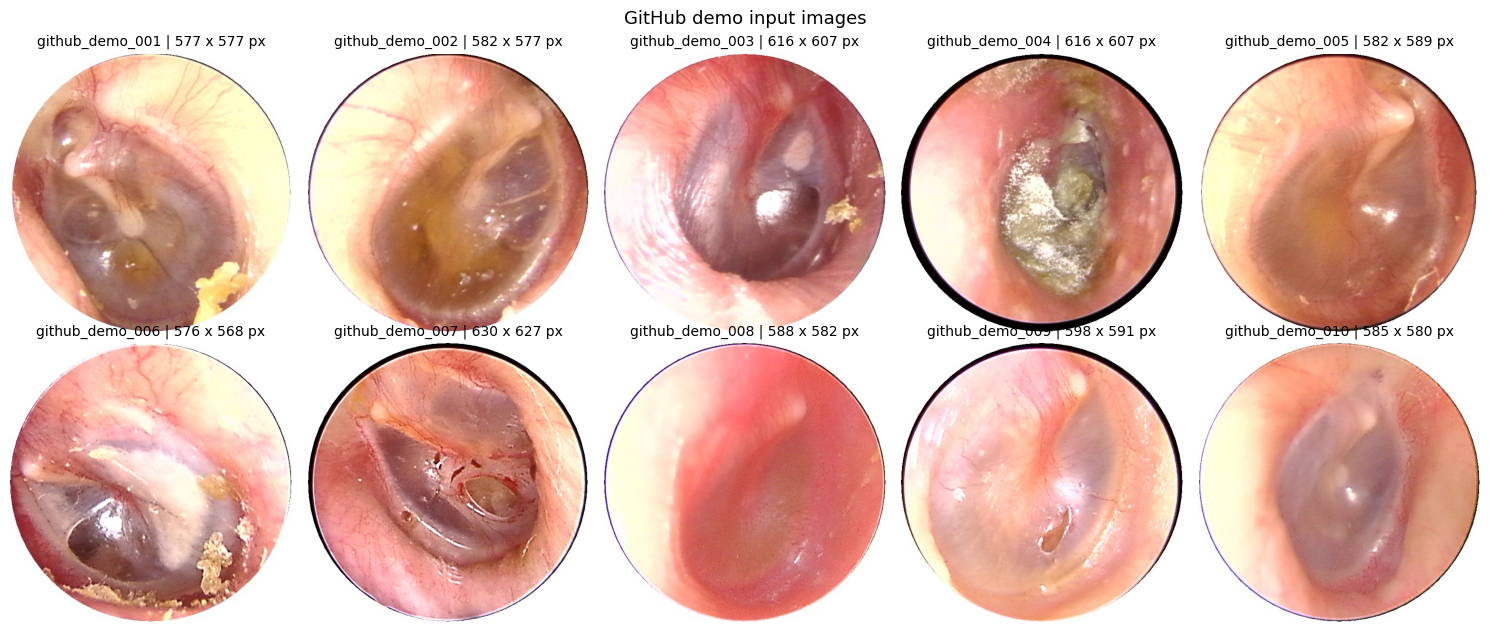

In [3]:
def show_image_gallery(items: list[dict[str, Any]], title: str) -> None:
    n_cols = 5
    n_rows = math.ceil(len(items) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.2 * n_rows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
    for ax in axes[len(items):]:
        ax.axis("off")
    for ax, item in zip(axes, items):
        ax.imshow(item["image"])
        ax.set_title(f"{item['path'].stem} | {item['size'][0]} x {item['size'][1]} px", fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


show_image_gallery(loaded_images, "GitHub demo input images")


## 4. Detector Initialization

The notebook loads a YOLO checkpoint with Ultralytics and runs model inference.


In [4]:
if YOLO is None:
    raise ImportError("Install ultralytics to run YOLO inference: pip install ultralytics")
if not WEIGHTS_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {WEIGHTS_PATH}. Provide a checkpoint or update WEIGHTS_PATH.")

detector = YOLO(str(WEIGHTS_PATH))
run_mode = "yolo_checkpoint_loaded"
print("Run mode:", run_mode)


Run mode: yolo_checkpoint_loaded


## 5. Inference and Post-processing

This cell runs `YOLO.predict` with the configured image size and confidence/IoU thresholds, then converts detections into a tabular schema.


In [5]:
def xyxy_to_xywhn(xyxy: list[float], image_size: tuple[int, int]) -> dict[str, float]:
    width, height = image_size
    x1, y1, x2, y2 = xyxy
    box_w = max(x2 - x1, 0.0)
    box_h = max(y2 - y1, 0.0)
    return {
        "x_center_norm": ((x1 + x2) / 2.0) / max(width, 1),
        "y_center_norm": ((y1 + y2) / 2.0) / max(height, 1),
        "width_norm": box_w / max(width, 1),
        "height_norm": box_h / max(height, 1),
    }


def make_detection_record(
    image_path: Path,
    detection_id: int,
    class_id: int,
    confidence: float,
    xyxy: list[float],
    image_size: tuple[int, int],
) -> dict[str, Any]:
    x1, y1, x2, y2 = [float(v) for v in xyxy]
    record = {
        "image_path": display_path(image_path),
        "image_name": image_path.name,
        "image_width": int(image_size[0]),
        "image_height": int(image_size[1]),
        "detection_id": int(detection_id),
        "class_id": int(class_id),
        "class_name": CLASS_NAMES.get(int(class_id), str(class_id)),
        "confidence": float(confidence),
        "x1": x1,
        "y1": y1,
        "x2": x2,
        "y2": y2,
        "run_mode": run_mode,
        "prediction_source": "model_prediction",
    }
    record.update(xyxy_to_xywhn([x1, y1, x2, y2], image_size))
    return record


def ultralytics_result_to_records(result: Any, image_path: Path) -> list[dict[str, Any]]:
    image = ImageOps.exif_transpose(Image.open(image_path)).convert("RGB")
    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        return []

    xyxy_values = boxes.xyxy.detach().cpu().tolist()
    conf_values = boxes.conf.detach().cpu().tolist()
    cls_values = boxes.cls.detach().cpu().tolist()
    records = []
    for idx, (xyxy, confidence, class_id) in enumerate(zip(xyxy_values, conf_values, cls_values)):
        records.append(make_detection_record(image_path, idx, int(class_id), confidence, xyxy, image.size))
    return records


results = detector.predict(
    source=[str(path) for path in image_paths],
    imgsz=IMG_SIZE,
    conf=CONF_THRESHOLD,
    iou=IOU_THRESHOLD,
    device=DEVICE,
    save=False,
    verbose=False,
)

all_records: list[dict[str, Any]] = []
for path, result in zip(image_paths, results):
    all_records.extend(ultralytics_result_to_records(result, path))

detections = pd.DataFrame(all_records)
detections


,image_path,image_name,image_width,image_height,detection_id,class_id,class_name,confidence,x1,y1,x2,y2,run_mode,prediction_source,x_center_norm,y_center_norm,width_norm,height_norm
0,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,0,3,CE,0.973925,373.620789,426.300568,490.546631,566.388428,yolo_checkpoint_loaded,model_prediction,0.748845,0.860216,0.202644,0.242787
1,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,1,10,PF,0.969806,63.599777,105.501083,189.823044,235.710617,yolo_checkpoint_loaded,model_prediction,0.219604,0.295677,0.218758,0.225666
2,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,2,0,TM,0.959373,48.346069,96.116554,514.455872,576.148560,yolo_checkpoint_loaded,model_prediction,0.487697,0.582552,0.807816,0.831945
3,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,3,3,CE,0.953510,159.095734,495.548584,192.129120,535.584595,yolo_checkpoint_loaded,model_prediction,0.304354,0.893530,0.057250,0.069387
4,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,4,6,ACTM,0.945535,90.480309,248.958252,359.648376,482.836151,yolo_checkpoint_loaded,model_prediction,0.390060,0.634137,0.466496,0.405334
5,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,5,3,CE,0.911651,235.320145,502.708496,265.511047,530.990845,yolo_checkpoint_loaded,model_prediction,0.433996,0.895753,0.052324,0.049016
6,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,6,1,SPM,0.840745,107.103271,199.247513,157.998856,261.661255,yolo_checkpoint_loaded,model_prediction,0.229725,0.399401,0.088207,0.108169
7,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_002.jpg,582,577,0,0,TM,0.978656,113.863014,43.136978,547.453064,562.720337,yolo_checkpoint_loaded,model_prediction,0.568141,0.525006,0.745000,0.900491
8,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_002.jpg,582,577,1,6,ACTM,0.929127,159.952820,166.593506,444.803101,531.081055,yolo_checkpoint_loaded,model_prediction,0.519550,0.604571,0.489433,0.631694
9,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_002.jpg,582,577,2,3,CE,0.907451,350.456848,439.802094,386.587952,473.253937,yolo_checkpoint_loaded,model_prediction,0.633200,0.791210,0.062081,0.057975


## 6. Detection Visualization

The visualization overlays post-processed boxes and class/confidence labels on each input image. This is an inference workflow display, not a substitute for clinical review.


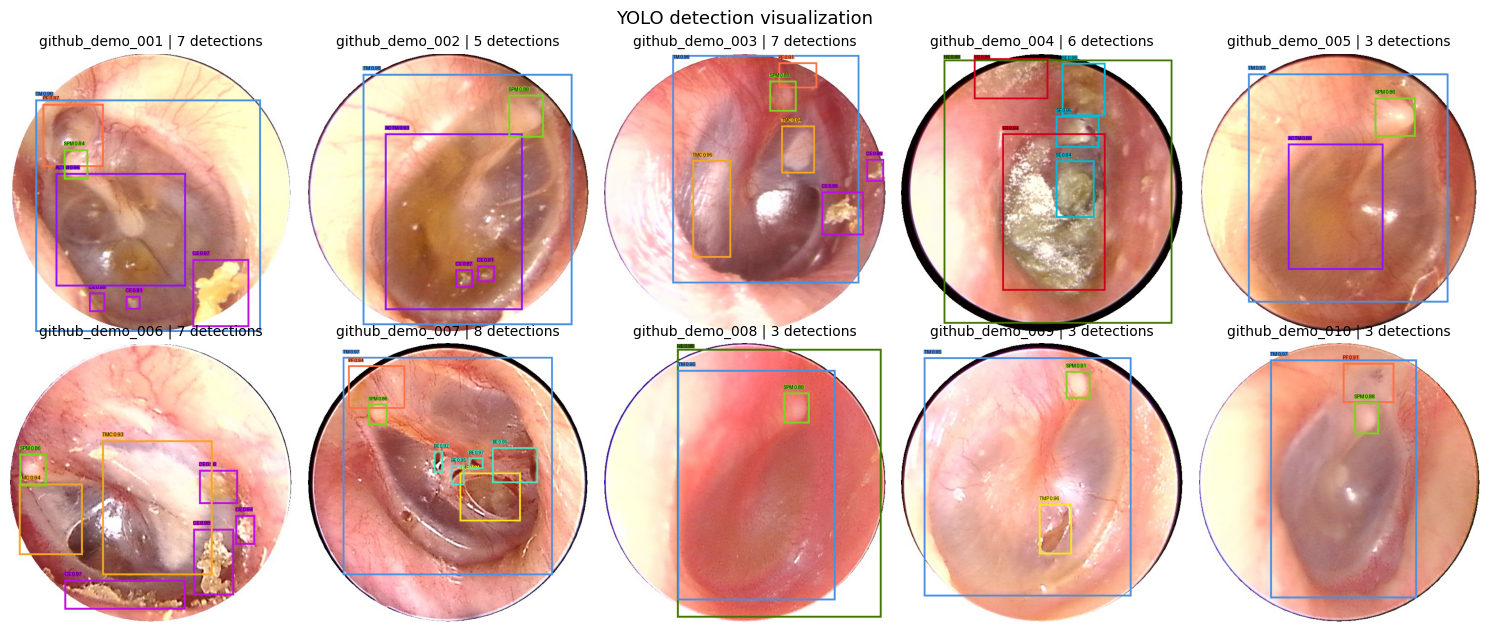

[PosixPath('demo_outputs/github_demo_001_detections.png'),
 PosixPath('demo_outputs/github_demo_002_detections.png'),
 PosixPath('demo_outputs/github_demo_003_detections.png'),
 PosixPath('demo_outputs/github_demo_004_detections.png'),
 PosixPath('demo_outputs/github_demo_005_detections.png'),
 PosixPath('demo_outputs/github_demo_006_detections.png'),
 PosixPath('demo_outputs/github_demo_007_detections.png'),
 PosixPath('demo_outputs/github_demo_008_detections.png'),
 PosixPath('demo_outputs/github_demo_009_detections.png'),
 PosixPath('demo_outputs/github_demo_010_detections.png')]

In [6]:
def draw_detections(image_path: Path, image_records: pd.DataFrame, output_path: Path) -> Path:
    image = ImageOps.exif_transpose(Image.open(image_path)).convert("RGB")
    draw = ImageDraw.Draw(image)
    for row in image_records.itertuples(index=False):
        class_id = int(row.class_id)
        color = PALETTE.get(class_id, (255, 255, 255))
        x1, y1, x2, y2 = float(row.x1), float(row.y1), float(row.x2), float(row.y2)
        label = f"{row.class_name} {float(row.confidence):.2f}"
        draw.rectangle((x1, y1, x2, y2), outline=color, width=4)
        text_y = max(0, y1 - 18)
        text_bbox = draw.textbbox((x1, text_y), label)
        draw.rectangle(text_bbox, fill=color)
        draw.text((x1, text_y), label, fill=(0, 0, 0))
    output_path.parent.mkdir(parents=True, exist_ok=True)
    image.save(output_path)
    return output_path


annotated_items = []
for path in image_paths:
    image_records = detections[detections["image_path"] == display_path(path)] if not detections.empty else pd.DataFrame()
    out_path = OUTPUT_DIR / f"{path.stem}_detections.png"
    annotated_items.append(
        {
            "path": path,
            "annotated_path": draw_detections(path, image_records, out_path),
            "num_detections": int(len(image_records)),
        }
    )

annotated_paths = [item["annotated_path"] for item in annotated_items]

n_cols = 5
n_rows = math.ceil(len(annotated_items) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.2 * n_rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
for ax in axes[len(annotated_items):]:
    ax.axis("off")
for ax, item in zip(axes, annotated_items):
    ax.imshow(Image.open(item["annotated_path"]))
    ax.set_title(f"{item['path'].stem} | {item['num_detections']} detections", fontsize=10)
    ax.axis("off")
fig.suptitle("YOLO detection visualization", fontsize=13)
fig.tight_layout()
plt.show()

annotated_paths


## 7. Structured Output Generation

The demo writes a detection-level CSV and a JSON payload that records the run mode, thresholds, class names, input split, and annotated-image artifacts.


In [7]:
csv_path = OUTPUT_DIR / "eleflai_yolo_demo_detections.csv"
json_path = OUTPUT_DIR / "eleflai_yolo_demo_outputs.json"

detections.to_csv(csv_path, index=False)

payload = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_family": "Ultralytics YOLO object detector",
    "run_mode": run_mode,
    "weights_path": display_path(WEIGHTS_PATH),
    "dataset_yaml": display_path(DATA_YAML_PATH),
    "dataset_split": YAML_SPLIT,
    "img_size": IMG_SIZE,
    "conf_threshold": CONF_THRESHOLD,
    "iou_threshold": IOU_THRESHOLD,
    "class_names": CLASS_NAMES,
    "num_images": len(image_paths),
    "num_detections": int(len(detections)),
    "clinical_use_notice": (
        "This notebook is provided for inference-workflow transparency only. It is not a stand-alone "
        "diagnostic device and should not be used for patient care without appropriate regulatory, "
        "clinical, and user validation."
    ),
    "detections": all_records,
    "artifacts": {
        "csv": str(csv_path),
        "json": str(json_path),
        "annotated_images": [str(path) for path in annotated_paths],
    },
}
json_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")

print("Wrote:")
print("-", csv_path)
print("-", json_path)
for path in annotated_paths:
    print("-", path)
detections


Wrote:
- demo_outputs/eleflai_yolo_demo_detections.csv
- demo_outputs/eleflai_yolo_demo_outputs.json
- demo_outputs/github_demo_001_detections.png
- demo_outputs/github_demo_002_detections.png
- demo_outputs/github_demo_003_detections.png
- demo_outputs/github_demo_004_detections.png
- demo_outputs/github_demo_005_detections.png
- demo_outputs/github_demo_006_detections.png
- demo_outputs/github_demo_007_detections.png
- demo_outputs/github_demo_008_detections.png
- demo_outputs/github_demo_009_detections.png
- demo_outputs/github_demo_010_detections.png


,image_path,image_name,image_width,image_height,detection_id,class_id,class_name,confidence,x1,y1,x2,y2,run_mode,prediction_source,x_center_norm,y_center_norm,width_norm,height_norm
0,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,0,3,CE,0.973925,373.620789,426.300568,490.546631,566.388428,yolo_checkpoint_loaded,model_prediction,0.748845,0.860216,0.202644,0.242787
1,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,1,10,PF,0.969806,63.599777,105.501083,189.823044,235.710617,yolo_checkpoint_loaded,model_prediction,0.219604,0.295677,0.218758,0.225666
2,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,2,0,TM,0.959373,48.346069,96.116554,514.455872,576.148560,yolo_checkpoint_loaded,model_prediction,0.487697,0.582552,0.807816,0.831945
3,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,3,3,CE,0.953510,159.095734,495.548584,192.129120,535.584595,yolo_checkpoint_loaded,model_prediction,0.304354,0.893530,0.057250,0.069387
4,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,4,6,ACTM,0.945535,90.480309,248.958252,359.648376,482.836151,yolo_checkpoint_loaded,model_prediction,0.390060,0.634137,0.466496,0.405334
5,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,5,3,CE,0.911651,235.320145,502.708496,265.511047,530.990845,yolo_checkpoint_loaded,model_prediction,0.433996,0.895753,0.052324,0.049016
6,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_001.jpg,577,577,6,1,SPM,0.840745,107.103271,199.247513,157.998856,261.661255,yolo_checkpoint_loaded,model_prediction,0.229725,0.399401,0.088207,0.108169
7,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_002.jpg,582,577,0,0,TM,0.978656,113.863014,43.136978,547.453064,562.720337,yolo_checkpoint_loaded,model_prediction,0.568141,0.525006,0.745000,0.900491
8,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_002.jpg,582,577,1,6,ACTM,0.929127,159.952820,166.593506,444.803101,531.081055,yolo_checkpoint_loaded,model_prediction,0.519550,0.604571,0.489433,0.631694
9,demo_assets/github_demo_yolo_dataset/images/de...,github_demo_002.jpg,582,577,2,3,CE,0.907451,350.456848,439.802094,386.587952,473.253937,yolo_checkpoint_loaded,model_prediction,0.633200,0.791210,0.062081,0.057975


## 8. Running with YOLO Weights

1. Place an authorized or local demo checkpoint at `weights/eleflai_yolo_demo.pt`, or update `WEIGHTS_PATH`.
2. Keep `DATA_YAML_PATH="demo_assets/github_demo_dataset.yaml"` and `YAML_SPLIT="demo"` to run the included 10-image GitHub demo, or set `IMAGE_PATHS` to other de-identified local otoscopic images.
3. Install dependencies with `pip install ultralytics pillow pandas matplotlib`.
